# Régression ADOS for Skeleton

In [ ]:
# 1. CONFIGURATION

import os, sys, json, time, gc, pickle, random, warnings
from itertools import combinations
from concurrent.futures import ProcessPoolExecutor, wait, FIRST_COMPLETED
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.ensemble import (RandomForestRegressor, AdaBoostRegressor,
                              ExtraTreesRegressor, RandomForestClassifier)
from sklearn.tree import ExtraTreeRegressor
from sklearn.feature_selection import RFE
from sklearn.preprocessing import LabelEncoder, Normalizer
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             precision_score, recall_score, f1_score,
                             accuracy_score, roc_auc_score)
warnings.filterwarnings("ignore")

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(it, **kw): return it

PROFILE = "fast"

if PROFILE == "article":
    ADA_N_ESTIMATORS, RF_N_ESTIMATORS = 50, 50
    TREE_MAX_TRAIN_ROWS = None
else:
    ADA_N_ESTIMATORS, RF_N_ESTIMATORS = 10, 20
    TREE_MAX_TRAIN_ROWS = 60_000        

ET_USE_ENSEMBLE = False     
ET_N_ESTIMATORS = 100       

N_FOLDS        = 5
SEED           = 42
SEGMENT_SIZE   = 25
SEQ_LEN        = 20
N_TO_EXCLUDE   = 7         
N_TEST_PARTICIPANTS = 8     
N_RFE_FEATURES = 53

# Deep learning 
HIDDEN_MLP, DROPOUT_MLP = [128, 64], 0.4
CONV_CH, KSIZE, LSTM_H, DROPOUT_SEQ = (64, 32), 3, 64, 0.3
LR, WD = 1e-3, 1e-4
LAMBDA_ADOS = 0.3
MAX_EPOCHS, PATIENCE = 150, 20
BS_SEQ, BS_MLP = 8, 256     # MLP : batch plus grand 
MLP_MAX_TRAIN_ROWS = 100_000
INNER_VAL_FRAC = 0.2        

OUT_DIR = '/kaggle/working' if os.path.isdir('/kaggle/working') else '.'
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
print("Device :", DEVICE, "| PROFILE :", PROFILE, "| sortie :", OUT_DIR)

Device : cuda | PROFILE : fast | sortie : /kaggle/working


In [ ]:
# 2. LOCALISATION DU DATASET DREAM
import zipfile
DATA_DIR_OVERRIDE = None    

def find_dream_root(base):
    best_root, best_count = None, 0
    for root, dirs, files in os.walk(base):
        json_subdirs = [d for d in dirs if any(f.endswith('.json')
                        for f in os.listdir(os.path.join(root, d))
                        if os.path.isfile(os.path.join(root, d, f)))]
        if json_subdirs:
            total = sum(len([f for f in os.listdir(os.path.join(root, d)) if f.endswith('.json')])
                        for d in json_subdirs)
            if total > best_count:
                best_root, best_count = root, total
    return best_root

def extract_all_zips_recursive(base):
    while True:
        zips = [os.path.join(r, f) for r, _, fs in os.walk(base) for f in fs if f.lower().endswith('.zip')]
        if not zips: break
        for z in zips:
            with zipfile.ZipFile(z) as zf: zf.extractall(os.path.dirname(z))
            os.remove(z)

if DATA_DIR_OVERRIDE:
    extract_path = DATA_DIR_OVERRIDE
else:
    extract_path = find_dream_root('/kaggle/input')
    if extract_path is None:    
        zips = [os.path.join(r, f) for r, _, fs in os.walk('/kaggle/input') for f in fs if f.lower().endswith('.zip')]
        if zips:
            tmp = '/kaggle/working/DREAM'; os.makedirs(tmp, exist_ok=True)
            for z in zips:
                with zipfile.ZipFile(z) as zf: zf.extractall(tmp)
            extract_all_zips_recursive(tmp)
            extract_path = find_dream_root(tmp)
if extract_path is None:
    raise RuntimeError("Dataset DREAM introuvable : ajoutez-le via 'Add Data' (ou renseignez DATA_DIR_OVERRIDE).")
print("Dataset DREAM :", extract_path)

Dataset DREAM : /kaggle/input/datasets/rymjaballah/dream-dataset/snd1156-1-1/data/DREAM2020_SND1156-001-V1.0/DREAMdataset


In [ ]:
# 3. EXTRACTION DES FEATURES 
JOINTS = ['Head','ShoulderCenter','ShoulderLeft','ShoulderRight','ElbowLeft','ElbowRight',
          'WristLeft','WristRight','HandLeft','HandRight']
JOINT_MAP_RAW = {'head':'Head','sholder_center':'ShoulderCenter','sholder_left':'ShoulderLeft',
                 'sholder_right':'ShoulderRight','elbow_left':'ElbowLeft','elbow_right':'ElbowRight',
                 'wrist_left':'WristLeft','wrist_right':'WristRight','hand_left':'HandLeft','hand_right':'HandRight'}
ANGLE_TRIPLETS = [('Head','ShoulderCenter','ShoulderLeft'),('Head','ShoulderCenter','ShoulderRight'),
    ('ShoulderLeft','ShoulderCenter','ShoulderRight'),('ShoulderCenter','ShoulderLeft','ElbowLeft'),
    ('ShoulderCenter','ShoulderRight','ElbowRight'),('ShoulderLeft','ElbowLeft','WristLeft'),
    ('ShoulderRight','ElbowRight','WristRight'),('ElbowLeft','WristLeft','HandLeft'),
    ('ElbowRight','WristRight','HandRight')]

def safe_first(o):
    if isinstance(o, list): return o[0] if o else {}
    return o if o is not None else {}

def assign_label(module, comm, inter):
    try: module = int(module)
    except (TypeError, ValueError): module = 1
    total = (comm or 0) + (inter or 0)
    asd_cut, aut_cut = {1:(7,12), 2:(8,12), 3:(7,10)}.get(module, (7,12))
    if total >= aut_cut: return 'Autistic Disorder'
    if total >= asd_cut: return 'ASD (AS, PDD)'
    return None

def euclidean_dist(A, B): return float(np.sqrt(np.sum((A - B) ** 2)))

def angle_between(P1, P2, P3):
    v1, v2 = P1 - P2, P3 - P2
    c = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2) + 1e-9)
    return float(np.degrees(np.arccos(np.clip(c, -1, 1))))

def to_float_array(lst):
    if not lst: return np.empty(0, dtype=float)
    return pd.to_numeric(pd.Series(lst), errors='coerce').to_numpy(dtype=float)

def build_xyz_array(d, keys):
    cols = [to_float_array(d.get(k, [])) for k in keys]
    n = max((len(c) for c in cols), default=0)
    if n == 0: return None
    out = np.full((n, len(keys)), np.nan)
    for i, c in enumerate(cols): out[:len(c), i] = c
    return out

def extract_features_arrays(seg, gaze, normative):
    f = {}
    means = {j: seg[j].mean(axis=0) for j in JOINTS}
    for a, b in combinations(JOINTS, 2):
        f[f'{a}_{b}_dist'] = euclidean_dist(means[a], means[b])
    for p1, p2, p3 in ANGLE_TRIPLETS:
        f[f'{p1}_{p2}_{p3}_angle'] = angle_between(means[p1], means[p2], means[p3])
    vectors = {}
    for name in ['head', 'eye']:
        G = gaze.get(name)
        if G is not None and G.shape[0] > 0:
            g = G.mean(axis=0); mag = np.linalg.norm(g) + 1e-9
            f[f'{name}_alpha'] = float(np.degrees(np.arccos(np.clip(g[0]/mag, -1, 1))))
            f[f'{name}_beta']  = float(np.degrees(np.arccos(np.clip(g[1]/mag, -1, 1))))
            f[f'{name}_gamma'] = float(np.degrees(np.arccos(np.clip(g[2]/mag, -1, 1))))
            vectors[name] = g
        else:
            f[f'{name}_alpha'] = f[f'{name}_beta'] = f[f'{name}_gamma'] = np.nan
    if 'head' in vectors and 'eye' in vectors:
        H, E = vectors['head'], vectors['eye']
        Hm, Em = np.linalg.norm(H) + 1e-9, np.linalg.norm(E) + 1e-9
        th = np.arccos(np.clip(np.dot(E, H) / (Em * Hm), -1, 1))
        f['gaze_angle_EH'] = float(np.degrees(th))
        f['gaze_zone_phi'] = float(np.degrees(np.arctan2(Hm*np.sin(th), Em + Hm*np.cos(th))))
    else:
        f['gaze_angle_EH'] = f['gaze_zone_phi'] = np.nan
    for j in JOINTS:
        for i, ax in enumerate('xyz'):
            f[f'skeleton_{j.lower()}_{ax}_std'] = float(seg[j][:, i].std())
    for name in ['head', 'eye']:
        G = gaze.get(name)
        for i, ax in enumerate(['rx','ry','rz']):
            f[f'{name}_gaze_{ax}_std'] = float(G[:, i].std()) if G is not None else np.nan
    f.update(normative)
    return f

def _pad(a, n):
    if len(a) < n: a = np.vstack([a, np.full((n - len(a), 3), np.nan)])
    return a

def process_json_file(fpath):
    with open(fpath) as fh: data = json.load(fh)
    p = safe_first(data.get('participant', {}))
    ados = data.get('ados', {})
    ad = ados.get('preTest', {}) if isinstance(ados, dict) else {}
    t = data.get('task', {}) if isinstance(data.get('task'), dict) else {}
    comm, inter, module = ad.get('communication'), ad.get('interaction'), ad.get('module')
    label = assign_label(module, comm, inter)
    if label is None: return []
    pid = p.get('id', p.get('child_id'))
    age = p.get('ageInMonths', p.get('age_months'))
    gender = str(p.get('gender', 'unknown'))
    cond = data.get('condition', p.get('condition', 'SHT'))
    diff = t.get('difficultyLevel', t.get('task_ability', 0))
    abil = str(t.get('ability', t.get('task_ability', 'unknown')))
    ados_score = (comm or 0) + (inter or 0)
    skel, hg, eg = data.get('skeleton', {}), data.get('head_gaze', {}), data.get('eye_gaze', {})
    js = {}
    for raw, canon in JOINT_MAP_RAW.items():
        j = skel.get(raw, {})
        js[canon] = build_xyz_array(j, ('x','y','z')) if isinstance(j, dict) else None
    gs = {'head': build_xyz_array(hg, ('rx','ry','rz')), 'eye': build_xyz_array(eg, ('rx','ry','rz'))}
    lengths = [a.shape[0] for a in js.values() if a is not None] + [a.shape[0] for a in gs.values() if a is not None]
    if not lengths: return []
    n_segs = max(lengths) // SEGMENT_SIZE
    out = []
    for i in range(n_segs):
        s, e = i*SEGMENT_SIZE, (i+1)*SEGMENT_SIZE
        seg = {}
        for j in JOINTS:
            a = js[j]
            seg[j] = _pad(a[s:min(e, a.shape[0])], SEGMENT_SIZE) if (a is not None and s < a.shape[0]) \
                     else np.full((SEGMENT_SIZE, 3), np.nan)
        sg = {}
        for name, a in gs.items():
            sg[name] = _pad(a[s:min(e, a.shape[0])], SEGMENT_SIZE) if (a is not None and s < a.shape[0]) else None
        norm = {'participant_ageInMonths': age, 'age_group': 0, 'gender': gender,
                'task_ability': abil, 'task_difficulty': diff}
        f = extract_features_arrays(seg, sg, norm)
        f.update(participant_id=pid, label=label, ados_score=ados_score, age_months=age, condition=cond)
        out.append(f)
    return out

FEAT_CKPT = os.path.join(OUT_DIR, 'feat_checkpoint_missing_models.pkl')
all_json = [os.path.join(extract_path, u, f) for u in sorted(os.listdir(extract_path))
            if os.path.isdir(os.path.join(extract_path, u))
            for f in sorted(os.listdir(os.path.join(extract_path, u))) if f.endswith('.json')]
print("Fichiers JSON :", len(all_json))

if os.path.exists(FEAT_CKPT):
    with open(FEAT_CKPT, 'rb') as fh: feat_df = pickle.load(fh)
    print("Features rechargées depuis le checkpoint :", feat_df.shape)
else:
    N_WORKERS = max(1, min((os.cpu_count() or 2) - 1, 8))
    all_feats, errors = [], []
    t0 = time.time()
    with ProcessPoolExecutor(max_workers=N_WORKERS) as ex:
        futs = {ex.submit(process_json_file, fp): fp for fp in all_json}
        for fut in tqdm(futs, total=len(futs), desc="Extraction"):
            try: all_feats.extend(fut.result())
            except Exception as e: errors.append((futs[fut], str(e)))
    feat_df = pd.DataFrame(all_feats)
    feat_df['gender'] = LabelEncoder().fit_transform(feat_df['gender'].astype(str))
    feat_df['task_ability'] = LabelEncoder().fit_transform(feat_df['task_ability'].astype(str))
    feat_df['age_group'] = pd.cut(feat_df['age_months'], bins=5, labels=[0,1,2,3,4]).astype(int)
    feat_df['participant_ageInMonths'] = feat_df['age_months']
    with open(FEAT_CKPT, 'wb') as fh: pickle.dump(feat_df, fh)
    print(f"Extraction : {time.time()-t0:.0f}s | erreurs : {len(errors)}")

print("Segments :", len(feat_df), "| participants :", feat_df['participant_id'].nunique())
print("Labels   :", feat_df['label'].value_counts().to_dict())

Fichiers JSON : 3121


Extraction:   0%|          | 0/3121 [00:00<?, ?it/s]

Extraction : 1000s | erreurs : 0
Segments : 1012441 | participants : 61
Labels   : {'Autistic Disorder': 812169, 'ASD (AS, PDD)': 200272}


In [ ]:
# 4. PRÉTRAITEMENT : exclusion NaN, split train/test, imputation, RFE, normalisation L2
EXCLUDE = {'participant_id', 'label', 'ados_score', 'age_months', 'condition'}
FEATURE_COLS = [c for c in feat_df.columns if c not in EXCLUDE]
X_raw = feat_df[FEATURE_COLS].copy().dropna(axis=1, how='all')
FEATURE_COLS = list(X_raw.columns)

nan_rate = (feat_df.assign(**{c: X_raw[c] for c in FEATURE_COLS})
            .groupby('participant_id')[FEATURE_COLS].apply(lambda g: g.isna().mean().mean()))
excluded = nan_rate.sort_values(ascending=False).head(N_TO_EXCLUDE).index.tolist()
keep = ~feat_df['participant_id'].isin(excluded).values
feat_clean = feat_df.loc[keep].reset_index(drop=True)
X_raw = X_raw.loc[keep].reset_index(drop=True)
print("Participants exclus :", len(excluded), "| restants :", feat_clean['participant_id'].nunique())

part_label = feat_clean.groupby('participant_id')['label'].agg(lambda s: s.value_counts().idxmax())
train_ids, test_ids = train_test_split(part_label.index.to_numpy(), test_size=N_TEST_PARTICIPANTS,
                                       stratify=part_label.values, random_state=42)
train_mask = feat_clean['participant_id'].isin(train_ids).values
test_mask  = feat_clean['participant_id'].isin(test_ids).values

X_raw = X_raw.fillna(X_raw[train_mask].median(numeric_only=True))
le = LabelEncoder()
y_clf_all = le.fit_transform(feat_clean['label'])
y_reg_all = feat_clean['ados_score'].values.astype(float)

X_tr_raw, X_te_raw = X_raw.values[train_mask], X_raw.values[test_mask]
y_train_clf, y_train_reg = y_clf_all[train_mask], y_reg_all[train_mask]
train_pids = feat_clean['participant_id'].values[train_mask]

rfe = RFE(RandomForestClassifier(n_estimators=50, criterion='entropy', random_state=42, n_jobs=-1),
          n_features_to_select=min(N_RFE_FEATURES, X_tr_raw.shape[1]), step=5)
rfe.fit(X_tr_raw, y_train_clf)
X_train = Normalizer(norm='l2').fit_transform(rfe.transform(X_tr_raw)).astype(np.float32)
selected_features = [FEATURE_COLS[i] for i, s in enumerate(rfe.support_) if s]

print("X_train :", X_train.shape, "| classes :", le.classes_)
print("ADOS (train) : min/moy/max =", y_train_reg.min(), round(y_train_reg.mean(), 2), y_train_reg.max())
del X_raw, X_tr_raw, X_te_raw; gc.collect()

Participants exclus : 7 | restants : 54
X_train : (753604, 53) | classes : ['ASD (AS, PDD)' 'Autistic Disorder']
ADOS (train) : min/moy/max = 7.0 13.85 20.0


715

In [ ]:
# 5. FOLDS PAR PARTICIPANT 
uniq_pids = pd.unique(train_pids)
pid_label = np.array([np.bincount(y_train_clf[train_pids == p]).argmax() for p in uniq_pids])
pid_ados  = np.array([y_train_reg[train_pids == p][0] for p in uniq_pids])

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
FOLDS = []   # liste de (pids_train, pids_val)
for tr, va in skf.split(uniq_pids, pid_label):
    FOLDS.append((uniq_pids[tr], uniq_pids[va]))
for i, (a, b) in enumerate(FOLDS):
    print(f"Fold {i+1}: {len(a)} participants train / {len(b)} val "
          f"(val classes : {np.bincount(pid_label[np.isin(uniq_pids, b)], minlength=2).tolist()})")

#utilitaires de métriques / checkpoints
def reg_metrics(y, p):
    mse = mean_squared_error(y, p)
    return {'MAE': mean_absolute_error(y, p), 'RMSE': float(np.sqrt(mse)), 'MSE': mse,
            'R2': r2_score(y, p) if len(y) > 1 else np.nan}

def clf_metrics(y, pred, proba1):
    m = {'Pre': precision_score(y, pred, average='macro', zero_division=0),
         'Rec': recall_score(y, pred, average='macro', zero_division=0),
         'F1':  f1_score(y, pred, average='macro', zero_division=0),
         'Acc': accuracy_score(y, pred)}
    try: m['AUC'] = roc_auc_score(y, proba1)
    except ValueError: m['AUC'] = np.nan
    return m

def run_cv(name, fold_fn):
    """fold_fn(pids_tr, pids_va) -> dict de métriques. Reprise automatique via checkpoint JSON."""
    ck = os.path.join(OUT_DIR, f"cv_{name.replace(' ', '_').replace('+', '_')}.json")
    res = json.load(open(ck)) if os.path.exists(ck) else []
    for i in range(len(res), N_FOLDS):
        set_seed(SEED + i); t0 = time.time()
        res.append({k: float(v) for k, v in fold_fn(*FOLDS[i]).items()})
        json.dump(res, open(ck, 'w'))
        print(f"[{name}] fold {i+1}/{N_FOLDS} — {time.time()-t0:.0f}s — "
              + ", ".join(f"{k}={v:.3f}" for k, v in res[-1].items() if k in ('MAE','RMSE','R2','F1')))
    return res

Fold 1: 36 participants train / 10 val (val classes : [3, 7])
Fold 2: 37 participants train / 9 val (val classes : [2, 7])
Fold 3: 37 participants train / 9 val (val classes : [2, 7])
Fold 4: 37 participants train / 9 val (val classes : [2, 7])
Fold 5: 37 participants train / 9 val (val classes : [2, 7])


In [ ]:
# 6. MODÈLES À ARBRES — régression ADOS 
def make_boosted_rf_reg():
    return AdaBoostRegressor(
        estimator=RandomForestRegressor(n_estimators=RF_N_ESTIMATORS, random_state=42, n_jobs=-1),
        n_estimators=ADA_N_ESTIMATORS, learning_rate=1.0, random_state=42)

def make_extra_trees_reg():
    if ET_USE_ENSEMBLE:
        return ExtraTreesRegressor(n_estimators=ET_N_ESTIMATORS, random_state=42, n_jobs=-1)
    return ExtraTreeRegressor(random_state=42)

def tree_fold(make_model):
    def fn(p_tr, p_va):
        tr_idx = np.where(np.isin(train_pids, p_tr))[0]
        va_idx = np.where(np.isin(train_pids, p_va))[0]
        if TREE_MAX_TRAIN_ROWS and len(tr_idx) > TREE_MAX_TRAIN_ROWS:
            tr_idx = np.random.RandomState(42).choice(tr_idx, TREE_MAX_TRAIN_ROWS, replace=False)
        m = make_model(); m.fit(X_train[tr_idx], y_train_reg[tr_idx])
        return reg_metrics(y_train_reg[va_idx], m.predict(X_train[va_idx]))
    return fn

results = {}
results['Boosted RF']  = run_cv('Boosted RF',  tree_fold(make_boosted_rf_reg))
results['Extra Trees'] = run_cv('Extra Trees', tree_fold(make_extra_trees_reg))

[Boosted RF] fold 1/5 — 224s — MAE=3.858, RMSE=4.960, R2=-1.843
[Boosted RF] fold 2/5 — 206s — MAE=4.081, RMSE=4.788, R2=-0.754
[Boosted RF] fold 3/5 — 230s — MAE=3.131, RMSE=3.835, R2=0.008
[Boosted RF] fold 4/5 — 243s — MAE=3.898, RMSE=4.493, R2=-0.146
[Boosted RF] fold 5/5 — 224s — MAE=4.216, RMSE=4.675, R2=-0.665
[Extra Trees] fold 1/5 — 1s — MAE=4.342, RMSE=5.400, R2=-2.370
[Extra Trees] fold 2/5 — 1s — MAE=4.618, RMSE=5.480, R2=-1.298
[Extra Trees] fold 3/5 — 1s — MAE=3.556, RMSE=4.602, R2=-0.428
[Extra Trees] fold 4/5 — 1s — MAE=4.357, RMSE=5.492, R2=-0.711
[Extra Trees] fold 5/5 — 1s — MAE=4.529, RMSE=5.326, R2=-1.161


In [ ]:
# 7. DEEP LEARNING MULTI-TÂCHE (classification + régression ADOS)
def build_sequences(X, y_clf, y_reg, pids, seq_len=SEQ_LEN):
    up = pd.unique(pids); seqs, lens, yc, yr = [], [], [], []
    for p in up:
        m = pids == p; f = X[m]; n = f.shape[0]
        if n >= seq_len: seq, ln = f[:seq_len], seq_len
        else: seq, ln = np.vstack([f, np.zeros((seq_len-n, X.shape[1]), np.float32)]), n
        seqs.append(seq); lens.append(ln); yc.append(y_clf[m][0]); yr.append(y_reg[m][0])
    return (np.asarray(seqs, np.float32), np.asarray(lens), np.asarray(yc), np.asarray(yr), up)

SEQ_X, SEQ_L, SEQ_YC, SEQ_YR, SEQ_PIDS = build_sequences(X_train, y_train_clf, y_train_reg, train_pids)
n_feat, n_cls = X_train.shape[1], len(le.classes_)

class MLPMT(nn.Module):
    def __init__(self):
        super().__init__()
        layers, d = [], n_feat
        for h in HIDDEN_MLP: layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(DROPOUT_MLP)]; d = h
        self.trunk = nn.Sequential(*layers); self.cls = nn.Linear(d, n_cls); self.reg = nn.Linear(d, 1)
    def forward(self, x, lens=None):
        z = self.trunk(x); return self.cls(z), self.reg(z).squeeze(-1)

class LSTMMT(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(n_feat, LSTM_H, batch_first=True); self.drop = nn.Dropout(DROPOUT_SEQ)
        self.cls = nn.Linear(LSTM_H, n_cls); self.reg = nn.Linear(LSTM_H, 1)
    def forward(self, x, lens):
        pk = nn.utils.rnn.pack_padded_sequence(x, lens.cpu(), batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(pk); z = self.drop(h[-1]); return self.cls(z), self.reg(z).squeeze(-1)

class CNN1DMT(nn.Module):
    def __init__(self):
        super().__init__()
        layers, c = [], n_feat
        for o in CONV_CH: layers += [nn.Conv1d(c, o, KSIZE, padding=KSIZE//2), nn.BatchNorm1d(o), nn.ReLU(), nn.Dropout(DROPOUT_SEQ)]; c = o
        self.conv = nn.Sequential(*layers); self.cls = nn.Linear(c, n_cls); self.reg = nn.Linear(c, 1)
    def forward(self, x, lens):
        z = self.conv(x.transpose(1, 2)); T = z.size(2)
        mask = (torch.arange(T, device=z.device).unsqueeze(0) < lens.to(z.device).unsqueeze(1)).float().unsqueeze(1)
        z = (z * mask).sum(2) / mask.sum(2).clamp(min=1); return self.cls(z), self.reg(z).squeeze(-1)

def class_weights(y):
    c = np.bincount(y, minlength=n_cls).astype(float); c[c == 0] = 1
    return torch.tensor(len(y) / (n_cls * c), dtype=torch.float32)

def train_mt(model_cls, X, L, yc, yr, in_tr, in_va, batch_size):
    """Entraîne sur X[in_tr], early-stopping sur X[in_va] (validation INTERNE au train du fold,
    jamais sur le fold de test). Les cibles ADOS sont standardisées pour l'optimisation."""
    mu, sd = yr[in_tr].mean(), yr[in_tr].std() + 1e-8
    T = lambda a, dt: torch.as_tensor(a, dtype=dt).to(DEVICE)
    Xtr, Ltr, yctr, yrtr = T(X[in_tr], torch.float32), T(L[in_tr], torch.long), T(yc[in_tr], torch.long), T((yr[in_tr]-mu)/sd, torch.float32)
    Xva, Lva, ycva, yrva = T(X[in_va], torch.float32), T(L[in_va], torch.long), T(yc[in_va], torch.long), T((yr[in_va]-mu)/sd, torch.float32)
    model = model_cls().to(DEVICE)
    ce = nn.CrossEntropyLoss(weight=class_weights(yc[in_tr]).to(DEVICE)); mse = nn.MSELoss()
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WD)
    best, best_state, wait = float('inf'), None, 0
    for ep in range(MAX_EPOCHS):
        model.train(); perm = torch.randperm(len(Xtr), device=DEVICE)
        for i in range(0, len(perm), batch_size):
            b = perm[i:i+batch_size]
            if len(b) < 2: continue          
            opt.zero_grad(); lo, pr = model(Xtr[b], Ltr[b])
            (ce(lo, yctr[b]) + LAMBDA_ADOS * mse(pr, yrtr[b])).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            lo, pr = model(Xva, Lva); vl = (ce(lo, ycva) + LAMBDA_ADOS * mse(pr, yrva)).item()
        if vl < best: best, wait, best_state = vl, 0, {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE: break
    model.load_state_dict(best_state); model.eval()
    return model, mu, sd

@torch.no_grad()
def predict_mt(model, X, L, mu, sd, chunk=20000):
    outs_p, outs_r = [], []
    for i in range(0, len(X), chunk):
        lo, pr = model(torch.as_tensor(X[i:i+chunk], dtype=torch.float32).to(DEVICE),
                       torch.as_tensor(L[i:i+chunk], dtype=torch.long).to(DEVICE))
        outs_p.append(F.softmax(lo, 1).cpu().numpy()); outs_r.append(pr.cpu().numpy())
    return np.concatenate(outs_p), np.concatenate(outs_r) * sd + mu

def inner_split(pids_tr):
    """Découpe stratifiée des participants du train du fold en train interne / val interne."""
    lab = np.array([pid_label[uniq_pids == p][0] for p in pids_tr])
    try: a, b = train_test_split(np.arange(len(pids_tr)), test_size=INNER_VAL_FRAC, stratify=lab, random_state=SEED)
    except ValueError: a, b = train_test_split(np.arange(len(pids_tr)), test_size=INNER_VAL_FRAC, random_state=SEED)
    return pids_tr[a], pids_tr[b]

def seq_fold(model_cls):
    def fn(p_tr, p_va):
        p_in, p_iv = inner_split(p_tr)
        m = lambda ps: np.isin(SEQ_PIDS, ps)
        model, mu, sd = train_mt(model_cls, SEQ_X, SEQ_L, SEQ_YC, SEQ_YR, m(p_in), m(p_iv), BS_SEQ)
        pr, rg = predict_mt(model, SEQ_X[m(p_va)], SEQ_L[m(p_va)], mu, sd)
        y_c, y_r = SEQ_YC[m(p_va)], SEQ_YR[m(p_va)]
        return {**clf_metrics(y_c, pr.argmax(1), pr[:, 1]), **reg_metrics(y_r, rg)}
    return fn

def mlp_fold(p_tr, p_va):
    p_in, p_iv = inner_split(p_tr)
    idx_in = np.where(np.isin(train_pids, p_in))[0]; idx_iv = np.where(np.isin(train_pids, p_iv))[0]
    idx_va = np.where(np.isin(train_pids, p_va))[0]
    rs = np.random.RandomState(42)
    if MLP_MAX_TRAIN_ROWS and len(idx_in) > MLP_MAX_TRAIN_ROWS: idx_in = rs.choice(idx_in, MLP_MAX_TRAIN_ROWS, replace=False)
    if MLP_MAX_TRAIN_ROWS and len(idx_iv) > MLP_MAX_TRAIN_ROWS // 4: idx_iv = rs.choice(idx_iv, MLP_MAX_TRAIN_ROWS // 4, replace=False)
    dummy_L = np.ones(len(X_train), dtype=np.int64)
    sel = np.zeros(len(X_train), bool)
    model, mu, sd = train_mt(MLPMT, X_train, dummy_L, y_train_clf, y_train_reg,
                             np.isin(np.arange(len(X_train)), idx_in), np.isin(np.arange(len(X_train)), idx_iv), BS_MLP)
    pr, rg = predict_mt(model, X_train[idx_va], dummy_L[idx_va], mu, sd)
    # Régression/classification évaluées au niveau SEGMENT, comme pour les modèles à arbres
    return {**clf_metrics(y_train_clf[idx_va], pr.argmax(1), pr[:, 1]), **reg_metrics(y_train_reg[idx_va], rg)}

results['MLP']     = run_cv('MLP', mlp_fold)
results['LSTM']    = run_cv('LSTM', seq_fold(LSTMMT))
results['1D-CNN']  = run_cv('1D-CNN', seq_fold(CNN1DMT))

[MLP] fold 1/5 — 28s — F1=0.475, MAE=2.342, RMSE=2.865, R2=0.052
[MLP] fold 2/5 — 22s — F1=0.533, MAE=3.145, RMSE=3.845, R2=-0.131
[MLP] fold 3/5 — 20s — F1=0.735, MAE=3.066, RMSE=3.718, R2=0.067
[MLP] fold 4/5 — 20s — F1=0.614, MAE=3.501, RMSE=4.296, R2=-0.047
[MLP] fold 5/5 — 41s — F1=0.524, MAE=3.348, RMSE=4.003, R2=-0.220
[LSTM] fold 1/5 — 1s — F1=0.412, MAE=2.492, RMSE=3.098, R2=-0.137
[LSTM] fold 2/5 — 1s — F1=0.438, MAE=2.918, RMSE=3.474, R2=-0.023
[LSTM] fold 3/5 — 1s — F1=0.438, MAE=3.615, RMSE=4.237, R2=-0.021
[LSTM] fold 4/5 — 1s — F1=0.438, MAE=3.416, RMSE=4.059, R2=-0.044
[LSTM] fold 5/5 — 0s — F1=0.438, MAE=3.331, RMSE=3.741, R2=-0.003
[1D-CNN] fold 1/5 — 2s — F1=0.293, MAE=2.305, RMSE=2.841, R2=0.044
[1D-CNN] fold 2/5 — 1s — F1=0.308, MAE=3.736, RMSE=4.352, R2=-0.605
[1D-CNN] fold 3/5 — 0s — F1=0.438, MAE=3.712, RMSE=4.292, R2=-0.048
[1D-CNN] fold 4/5 — 0s — F1=0.438, MAE=3.221, RMSE=3.985, R2=-0.007
[1D-CNN] fold 5/5 — 1s — F1=0.679, MAE=3.956, RMSE=4.418, R2=-0.399


In [ ]:
# 8. TABLEAU FINAL 
def fmt(vals, key, pct=False, nd=3):
    v = np.array([r.get(key, np.nan) for r in vals], dtype=float)
    if np.all(np.isnan(v)): return "—"
    v = v * (100 if pct else 1)
    return f"{np.nanmean(v):.{2 if pct else nd}f} ± {np.nanstd(v):.{2 if pct else nd}f}"

order = ['Boosted RF', 'Extra Trees', 'MLP', 'LSTM', '1D-CNN']
rows = []
for name in order:
    r = results[name]
    rows.append({'Model': name,
                 'Pre. (%)': fmt(r,'Pre',True), 'Rec. (%)': fmt(r,'Rec',True), 'F1 (%)': fmt(r,'F1',True),
                 'Acc. (%)': fmt(r,'Acc',True), 'AUC': fmt(r,'AUC'),
                 'MAE': fmt(r,'MAE'), 'RMSE': fmt(r,'RMSE'), 'MSE': fmt(r,'MSE'), 'R²': fmt(r,'R2')})
final = pd.DataFrame(rows)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 20)
print(final.to_string(index=False))

final.to_csv(os.path.join(OUT_DIR, 'tableau_modeles_manquants.csv'), index=False)
pd.DataFrame([{**{'model': n, 'fold': i+1}, **r} for n, rs in results.items() for i, r in enumerate(rs)]
             ).to_csv(os.path.join(OUT_DIR, 'resultats_par_fold.csv'), index=False)
print("\nFichiers écrits dans", OUT_DIR, ": tableau_modeles_manquants.csv, resultats_par_fold.csv")

      Model      Pre. (%)      Rec. (%)        F1 (%)      Acc. (%)           AUC           MAE          RMSE            MSE             R²
 Boosted RF             —             —             —             —             — 3.837 ± 0.376 4.550 ± 0.389 20.856 ± 3.394 -0.680 ± 0.651
Extra Trees             —             —             —             —             — 4.280 ± 0.377 5.260 ± 0.334 27.780 ± 3.364 -1.194 ± 0.665
        MLP  58.51 ± 7.33  60.74 ± 9.01  57.63 ± 9.10 63.59 ± 10.69 0.690 ± 0.096 3.081 ± 0.399 3.745 ± 0.481 14.258 ± 3.399 -0.056 ± 0.109
       LSTM  38.11 ± 1.56  50.00 ± 0.00  43.24 ± 1.03  76.22 ± 3.11 0.452 ± 0.190 3.155 ± 0.402 3.722 ± 0.407 14.017 ± 2.995 -0.046 ± 0.047
     1D-CNN 43.29 ± 12.45 47.38 ± 12.92 43.08 ± 13.83 61.56 ± 20.39 0.505 ± 0.246 3.386 ± 0.591 3.978 ± 0.587 16.167 ± 4.234 -0.203 ± 0.254

Fichiers écrits dans /kaggle/working : tableau_modeles_manquants.csv, resultats_par_fold.csv


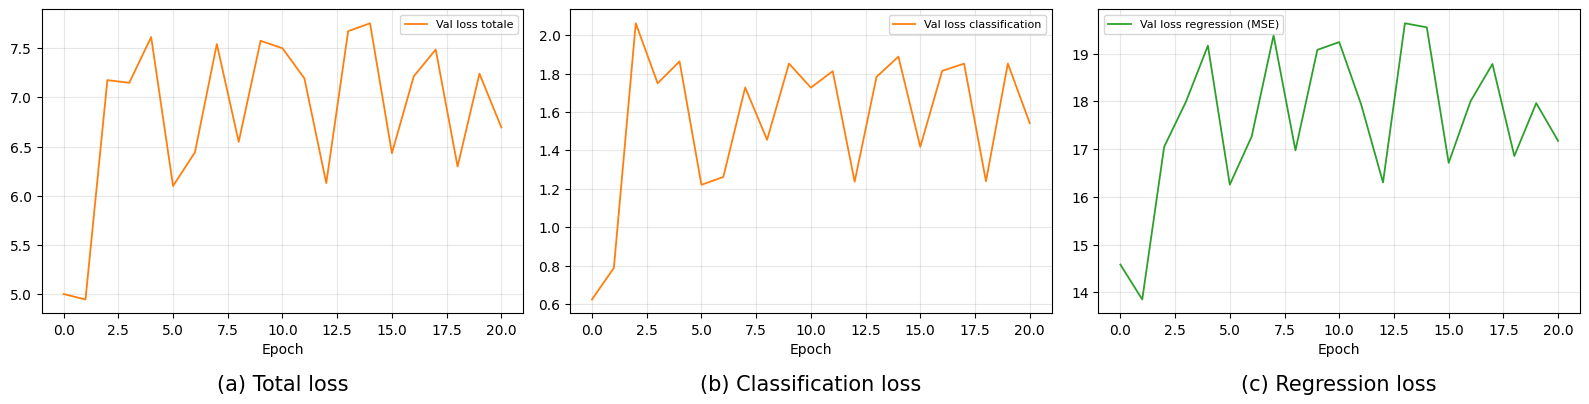

Epochs : 21 | meilleure epoch (val totale) : 1 | image : /kaggle/working/mlp_training_evolution.png


In [ ]:
# 9. COURBES D'ENTRAÎNEMENT DU MLP (val loss par epoch)
import matplotlib.pyplot as plt

FOLD_TO_PLOT = 0        # fold (0..4) dont on trace les courbes
ADOS_UNITS   = True     # True : MSE ADOS en unités d'origine (~10-14) et total = CE + λ·MSE 
                        # False: loss réellement optimisée (cibles ADOS standardisées, MSE ~ 1)

def train_mlp_with_history(p_tr):
    p_in, p_iv = inner_split(p_tr)
    idx_in = np.where(np.isin(train_pids, p_in))[0]
    idx_iv = np.where(np.isin(train_pids, p_iv))[0]
    rs = np.random.RandomState(42)
    if MLP_MAX_TRAIN_ROWS and len(idx_in) > MLP_MAX_TRAIN_ROWS:
        idx_in = rs.choice(idx_in, MLP_MAX_TRAIN_ROWS, replace=False)
    if MLP_MAX_TRAIN_ROWS and len(idx_iv) > MLP_MAX_TRAIN_ROWS // 4:
        idx_iv = rs.choice(idx_iv, MLP_MAX_TRAIN_ROWS // 4, replace=False)

    mu, sd = y_train_reg[idx_in].mean(), y_train_reg[idx_in].std() + 1e-8
    T = lambda a, dt: torch.as_tensor(a, dtype=dt).to(DEVICE)
    Xtr, yctr = T(X_train[idx_in], torch.float32), T(y_train_clf[idx_in], torch.long)
    yrtr = T((y_train_reg[idx_in] - mu) / sd, torch.float32)
    Xva, ycva = T(X_train[idx_iv], torch.float32), T(y_train_clf[idx_iv], torch.long)
    yrva = T((y_train_reg[idx_iv] - mu) / sd, torch.float32)

    model = MLPMT().to(DEVICE)
    ce, mse = nn.CrossEntropyLoss(weight=class_weights(y_train_clf[idx_in]).to(DEVICE)), nn.MSELoss()
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WD)
    hist = {'total': [], 'cls': [], 'reg': []}
    best, wait = float('inf'), 0
    for ep in range(MAX_EPOCHS):
        model.train(); perm = torch.randperm(len(Xtr), device=DEVICE)
        for i in range(0, len(perm), BS_MLP):
            b = perm[i:i+BS_MLP]
            if len(b) < 2: continue
            opt.zero_grad(); lo, pr = model(Xtr[b])
            (ce(lo, yctr[b]) + LAMBDA_ADOS * mse(pr, yrtr[b])).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            lo, pr = model(Xva)
            l_cls = ce(lo, ycva).item()
            l_reg_std = mse(pr, yrva).item()
        vl_opt = l_cls + LAMBDA_ADOS * l_reg_std          # critère d'early-stopping du notebook
        l_reg = l_reg_std * sd**2 if ADOS_UNITS else l_reg_std
        hist['cls'].append(l_cls); hist['reg'].append(l_reg)
        hist['total'].append(l_cls + LAMBDA_ADOS * l_reg)
        if vl_opt < best: best, wait = vl_opt, 0
        else:
            wait += 1
            if wait >= PATIENCE: break
    return hist

set_seed(SEED + FOLD_TO_PLOT)
hist = train_mlp_with_history(FOLDS[FOLD_TO_PLOT][0])
epochs = np.arange(len(hist['total']))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
panels = [('total', 'Val loss totale',            'tab:orange', '(a) Total loss'),
          ('cls',   'Val loss classification',    'tab:orange', '(b) Classification loss'),
          ('reg',   'Val loss regression (MSE)',  'tab:green',  '(c) Regression loss')]
for ax, (k, lab, col, cap) in zip(axes, panels):
    ax.plot(epochs, hist[k], color=col, lw=1.3, label=lab)
    ax.set_xlabel('Epoch'); ax.legend(loc='best', fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_title(cap, y=-0.28, fontsize=15)
plt.tight_layout()
out_png = os.path.join(OUT_DIR, 'mlp_training_evolution.png')
plt.savefig(out_png, dpi=200, bbox_inches='tight'); plt.show()
print("Epochs :", len(epochs), "| meilleure epoch (val totale) :", int(np.argmin(hist['total'])), "| image :", out_png)
